# Explainable AI for Diabetic Retinopathy Screening in Rural India
**Mid-term prototype** - APTOS 2019 Blindness Detection (Kaggle), 3,662 colour fundus images, 5 ICDR grades.

Pipeline: data audit -> EDA -> preprocessing -> MobileNetV2 transfer learning -> evaluation -> Grad-CAM explanations.

## 1. Environment check

In [1]:
# ===== Cell 1: GPU and internet check =====
# Purpose: confirm that the GPU accelerator and internet are switched on before any work starts.
# Output: TensorFlow version, list of GPUs, internet status.
import tensorflow as tf
import urllib.request, urllib.error

print("TensorFlow:", tf.__version__)
# list the GPUs that TensorFlow can see (the Kaggle T4 accelerator must be enabled)
gpus = tf.config.list_physical_devices("GPU")
print("GPU:", gpus if gpus else "NONE - Settings > Accelerator > GPU")

# internet is needed to download the ImageNet pre-trained weights
try:
    urllib.request.urlopen("https://storage.googleapis.com", timeout=8)
    print("Internet: ON")
# an HTTP error still means the server was reached, so internet is on
except urllib.error.HTTPError:
    print("Internet: ON")
except Exception as e:
    print("Internet: OFF - Settings > Internet > On (needed to download pretrained weights)")

TensorFlow: 2.21.0


GPU: NONE - Settings > Accelerator > GPU


Internet: ON


## 2. Data collection
Source: [APTOS 2019](https://www.kaggle.com/c/aptos2019-blindness-detection) (Aravind Eye Hospital, India). The labelled Kaggle train set (3,662 images) was split into train / validation / test CSVs.

In [2]:
from pathlib import Path

# Change this to the folder where you downloaded APTOS 2019.
DATASET_DIR = Path(r"C:\Users\shres\OneDrive\Desktop\Diabetic_Retinopathy_Screening\Diabetic_Retinopathy_Screening\DataBase")

print("Dataset folder exists:", DATASET_DIR.exists())

if DATASET_DIR.exists():
    print("\nFiles and folders:")

    for item in DATASET_DIR.iterdir():
        if item.is_dir():
            print(f"[FOLDER] {item.name}")
        else:
            print(f"[FILE]   {item.name}")

Dataset folder exists: True

Files and folders:
[FILE]   test.csv
[FOLDER] test_images
[FILE]   train_1.csv
[FOLDER] train_images
[FILE]   valid.csv
[FOLDER] val_images


In [3]:
import pandas as pd
files = {
    "Train": DATASET_DIR / "train_1.csv",
    "Validation": DATASET_DIR / "valid.csv",
    "Test": DATASET_DIR / "test.csv",
}

for name, path in files.items():
    print(f"\n{'=' * 15} {name} {'=' * 15}")

    df = pd.read_csv(path)

    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    print(df.head())

    if "diagnosis" in df.columns:
        print("\nClass distribution:")
        print(df["diagnosis"].value_counts().sort_index())


=============== Train ===============
Shape: (2930, 2)
Columns: ['id_code', 'diagnosis']
        id_code  diagnosis
0  1ae8c165fd53          2
1  1b329a127307          1
2  1b32e1d775ea          4
3  1b3647865779          0
4  1b398c0494d1          0

Class distribution:
diagnosis
0    1434
1     300
2     808
3     154
4     234
Name: count, dtype: int64

=============== Validation ===============
Shape: (366, 2)
Columns: ['id_code', 'diagnosis']
        id_code  diagnosis
0  000c1434d8d7          2
1  001639a390f0          4
2  0024cdab0c1e          1
3  002c21358ce6          0
4  005b95c28852          0

Class distribution:
diagnosis
0    172
1     40
2    104
3     22
4     28
Name: count, dtype: int64

=============== Test ===============
Shape: (366, 2)
Columns: ['id_code', 'diagnosis']
        id_code  diagnosis
0  e4dcca36ceb4          0
1  e4e343eaae2a          2
2  e4f12411fd85          4
3  e50b0174690d          0
4  e5197d77ec68          0

Class distribution:
diagnosis
0 

In [4]:
# ===== Cell 5: Shared settings and plot style =====
# Purpose: one place for paths, grade names and a consistent colour per DR grade.
import json
import numpy as np
import matplotlib.pyplot as plt

train_df = pd.read_csv(DATASET_DIR / "train_1.csv")
valid_df = pd.read_csv(DATASET_DIR / "valid.csv")
test_df = pd.read_csv(DATASET_DIR / "test.csv")

IMAGE_DIRS = {"train": DATASET_DIR / "train_images",
              "valid": DATASET_DIR / "val_images",
              "test": DATASET_DIR / "test_images"}

grade_labels = {0: "No DR", 1: "Mild", 2: "Moderate", 3: "Severe", 4: "Proliferative DR"}
# fixed colour per grade (same colour = same grade in every figure)
GRADE_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]

OUTPUT_DIR = Path("graphs"); OUTPUT_DIR.mkdir(exist_ok=True)
RESULTS_DIR = Path("results"); RESULTS_DIR.mkdir(exist_ok=True)

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#898781", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "text.color": "#0b0b0b",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "font.size": 10,
})

## 3. Data quality: missing values, duplicates, leakage, missing files

In [5]:
# ===== Cell 6: Data quality audit =====
# Purpose: make sure labels are complete, IDs are unique, splits do not overlap
# and every CSV row has an image on disk.
splits = {"train": train_df, "valid": valid_df, "test": test_df}
audit = []
for name, df in splits.items():
    files_on_disk = {p.stem for p in IMAGE_DIRS[name].glob("*.png")}
    audit.append({
        "split": name,
        "rows": len(df),
        "missing_values": int(df.isna().sum().sum()),
        "duplicate_ids": int(df["id_code"].duplicated().sum()),
        "invalid_labels": int((~df["diagnosis"].isin(range(5))).sum()),
        "missing_image_files": int((~df["id_code"].isin(files_on_disk)).sum()),
    })
audit_df = pd.DataFrame(audit)
print(audit_df.to_string(index=False))

# leakage check: an image must appear in only one split
ids = {k: set(v["id_code"]) for k, v in splits.items()}
print("\nTrain/Valid overlap:", len(ids["train"] & ids["valid"]))
print("Train/Test overlap :", len(ids["train"] & ids["test"]))
print("Valid/Test overlap :", len(ids["valid"] & ids["test"]))

split  rows  missing_values  duplicate_ids  invalid_labels  missing_image_files
train  2930               0              0               0                    0
valid   366               0              0               0                    0
 test   366               0              0               0                    0



Train/Valid overlap: 0
Train/Test overlap : 0
Valid/Test overlap : 0


## 4. Exploratory data analysis
### 4.1 Label distribution and split balance

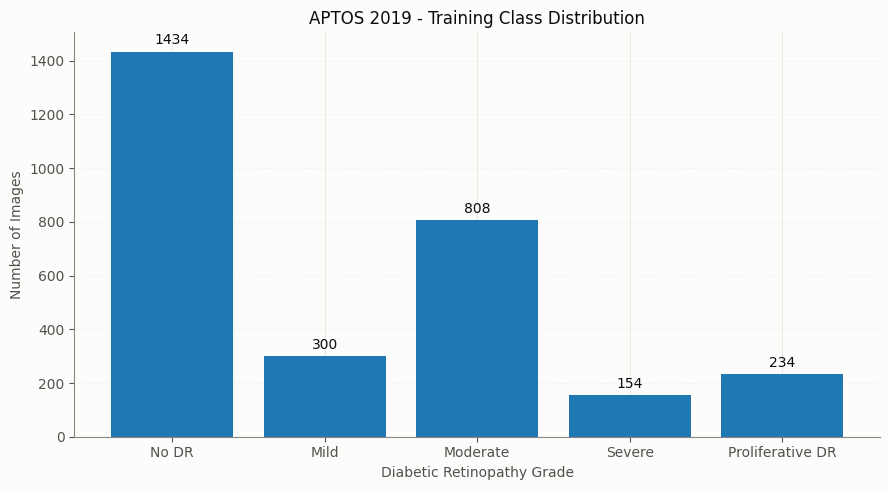

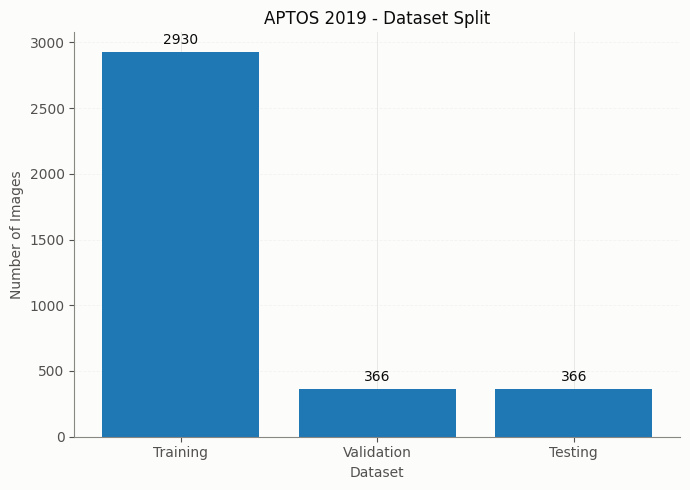

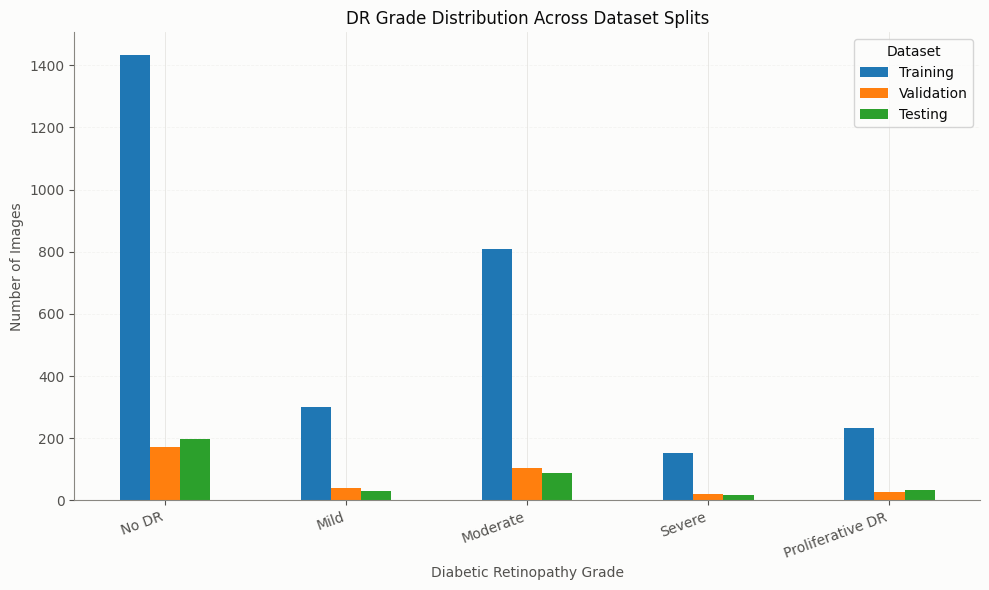

All graphs generated successfully!
Saved in: C:\Users\shres\OneDrive\Desktop\Diabetic_Retinopathy_Screening\Diabetic_Retinopathy_Screening\graphs


In [6]:
import matplotlib.pyplot as plt

# Load CSV files
train_df = pd.read_csv(DATASET_DIR / "train_1.csv")
valid_df = pd.read_csv(DATASET_DIR / "valid.csv")
test_df = pd.read_csv(DATASET_DIR / "test.csv")

# DR grade labels
grade_labels = {
    0: "No DR",
    1: "Mild",
    2: "Moderate",
    3: "Severe",
    4: "Proliferative DR"
}

# Create output directory for graphs
OUTPUT_DIR = Path("graphs")
OUTPUT_DIR.mkdir(exist_ok=True)


# --------------------------------------------------
# GRAPH 1: Class distribution in training dataset
# --------------------------------------------------

train_counts = (
    train_df["diagnosis"]
    .value_counts()
    .reindex(range(5), fill_value=0)
)

plt.figure(figsize=(9, 5))

bars = plt.bar(
    [grade_labels[i] for i in range(5)],
    train_counts.values
)

plt.title("APTOS 2019 - Training Class Distribution")
plt.xlabel("Diabetic Retinopathy Grade")
plt.ylabel("Number of Images")
plt.bar_label(bars, padding=3)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()

plt.savefig(OUTPUT_DIR / "class_distribution.png", dpi=300)
plt.show()


# --------------------------------------------------
# GRAPH 2: Dataset split
# --------------------------------------------------

split_names = ["Training", "Validation", "Testing"]
split_counts = [
    len(train_df),
    len(valid_df),
    len(test_df)
]

plt.figure(figsize=(7, 5))

bars = plt.bar(split_names, split_counts)

plt.title("APTOS 2019 - Dataset Split")
plt.xlabel("Dataset")
plt.ylabel("Number of Images")
plt.bar_label(bars, padding=3)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()

plt.savefig(OUTPUT_DIR / "dataset_split.png", dpi=300)
plt.show()


# --------------------------------------------------
# GRAPH 3: Compare class distributions
# --------------------------------------------------

class_comparison = pd.DataFrame({
    "Training": train_df["diagnosis"].value_counts(),
    "Validation": valid_df["diagnosis"].value_counts(),
    "Testing": test_df["diagnosis"].value_counts()
}).reindex(range(5), fill_value=0)

class_comparison.index = [
    grade_labels[i] for i in class_comparison.index
]

ax = class_comparison.plot(
    kind="bar",
    figsize=(10, 6)
)

ax.set_title("DR Grade Distribution Across Dataset Splits")
ax.set_xlabel("Diabetic Retinopathy Grade")
ax.set_ylabel("Number of Images")
ax.legend(title="Dataset")
ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.xticks(rotation=20, ha="right")
plt.tight_layout()

plt.savefig(OUTPUT_DIR / "class_comparison.png", dpi=300)
plt.show()


print("All graphs generated successfully!")
print("Saved in:", OUTPUT_DIR.resolve())

In [7]:
# ===== Cell 8: Class imbalance numbers =====
# Purpose: quantify the imbalance that the model has to cope with.
counts = train_df["diagnosis"].value_counts().sort_index()
imb = pd.DataFrame({"grade": [grade_labels[i] for i in counts.index],
                    "images": counts.values,
                    "percent": (100 * counts / counts.sum()).round(1).values})
print(imb.to_string(index=False))
print(f"\nImbalance ratio (largest / smallest class): {counts.max() / counts.min():.1f} : 1")
referable = (train_df["diagnosis"] >= 2).mean() * 100
print(f"Referable DR (grade >= 2) in training set: {referable:.1f}%")

           grade  images  percent
           No DR    1434     48.9
            Mild     300     10.2
        Moderate     808     27.6
          Severe     154      5.3
Proliferative DR     234      8.0

Imbalance ratio (largest / smallest class): 9.3 : 1
Referable DR (grade >= 2) in training set: 40.8%


### 4.2 Sample fundus images per grade

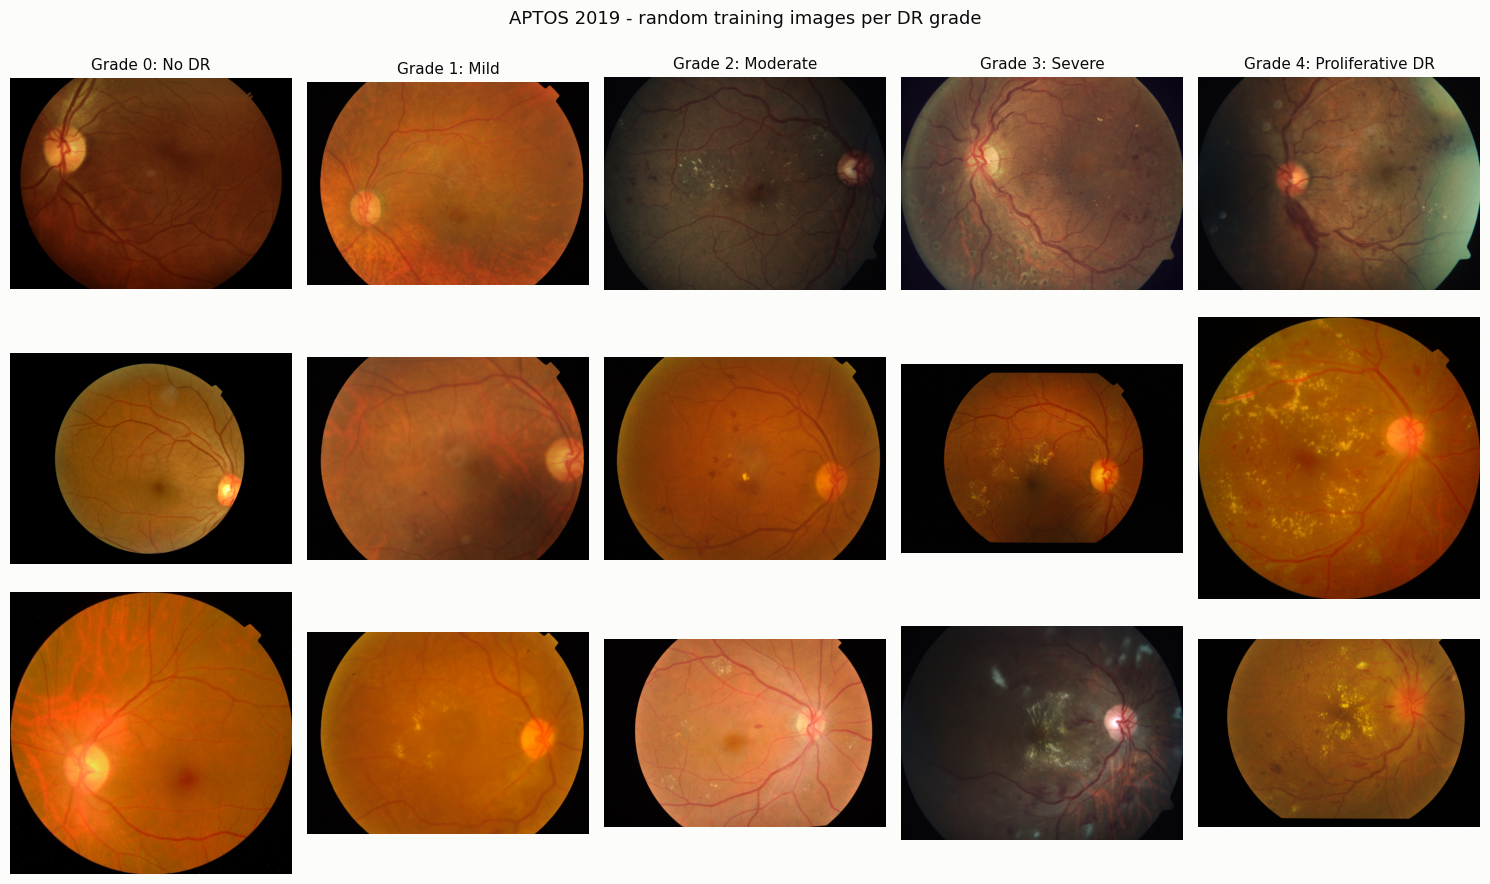

In [8]:
# ===== Cell 9: Sample images per grade =====
# Purpose: look at the raw data the model sees.
import cv2

def read_rgb(path):
    return cv2.cvtColor(cv2.imread(str(path)), cv2.COLOR_BGR2RGB)

fig, axes = plt.subplots(3, 5, figsize=(15, 9))
for g in range(5):
    ids_g = train_df[train_df["diagnosis"] == g]["id_code"].sample(3, random_state=42)
    for r, img_id in enumerate(ids_g):
        ax = axes[r, g]
        ax.imshow(read_rgb(IMAGE_DIRS["train"] / f"{img_id}.png"))
        ax.axis("off")
        if r == 0:
            ax.set_title(f"Grade {g}: {grade_labels[g]}", fontsize=11)
plt.suptitle("APTOS 2019 - random training images per DR grade", fontsize=13)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "sample_images.png", dpi=150)
plt.show()

### 4.3 Image resolution, brightness and outliers
Images come from many clinics and cameras, so resolution and illumination vary a lot. A stratified sample of 500 training images is profiled (reading all 2,930 high-resolution PNGs on CPU is slow).

In [9]:
# ===== Cell 10: Image-level statistics on a stratified sample =====
# Purpose: find resolution spread and badly exposed images (outliers).
sample_df = (train_df.groupby("diagnosis", group_keys=False)
             .apply(lambda d: d.sample(min(len(d), 100), random_state=0)))
rows = []
for img_id, g in zip(sample_df["id_code"], sample_df["diagnosis"]):
    img = cv2.imread(str(IMAGE_DIRS["train"] / f"{img_id}.png"))
    h, w = img.shape[:2]
    small = cv2.resize(img, (256, 256))
    gray = cv2.cvtColor(small, cv2.COLOR_BGR2GRAY)
    retina = gray[gray > 10]                       # ignore the black border
    rows.append({"id_code": img_id, "diagnosis": g, "width": w, "height": h,
                 "aspect": w / h, "brightness": retina.mean() if retina.size else 0,
                 "contrast": retina.std() if retina.size else 0,
                 "black_border_pct": 100 * (gray <= 10).mean()})
stats_df = pd.DataFrame(rows)
print(stats_df[["width", "height", "aspect", "brightness", "contrast", "black_border_pct"]].describe().round(1))

# IQR rule for exposure outliers
q1, q3 = stats_df["brightness"].quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
stats_df["outlier"] = (stats_df["brightness"] < low) | (stats_df["brightness"] > high)
print(f"\nBrightness IQR fence: [{low:.1f}, {high:.1f}]")
print(f"Exposure outliers: {stats_df['outlier'].sum()} of {len(stats_df)} sampled images "
      f"({100 * stats_df['outlier'].mean():.1f}%)")
print(f"Distinct resolutions in sample: {stats_df[['width','height']].drop_duplicates().shape[0]}")
stats_df.to_csv(RESULTS_DIR / "image_stats_sample.csv", index=False)

C:\Users\shres\AppData\Local\Temp\ipykernel_13516\1670116437.py:4: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda d: d.sample(min(len(d), 100), random_state=0)))


        width  height  aspect  brightness  contrast  black_border_pct
count   500.0   500.0   500.0       500.0     500.0             500.0
mean   2369.6  1728.6     1.3        85.6      17.3              21.3
std     820.1   510.6     0.2        19.7       6.2              11.1
min     474.0   358.0     1.0        29.4       7.3               0.4
25%    2048.0  1536.0     1.3        73.2      13.3              16.6
50%    2416.0  1736.0     1.4        86.3      15.9              20.8
75%    2896.0  1958.0     1.5        98.9      19.3              25.4
max    4288.0  2848.0     1.5       133.3      52.1              52.6

Brightness IQR fence: [34.6, 137.5]
Exposure outliers: 3 of 500 sampled images (0.6%)
Distinct resolutions in sample: 16


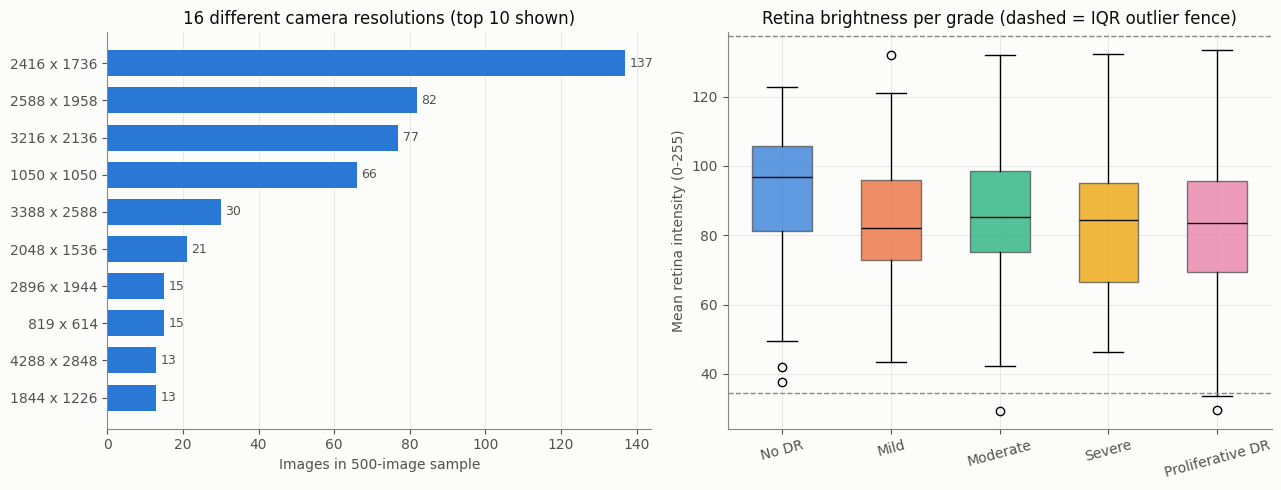

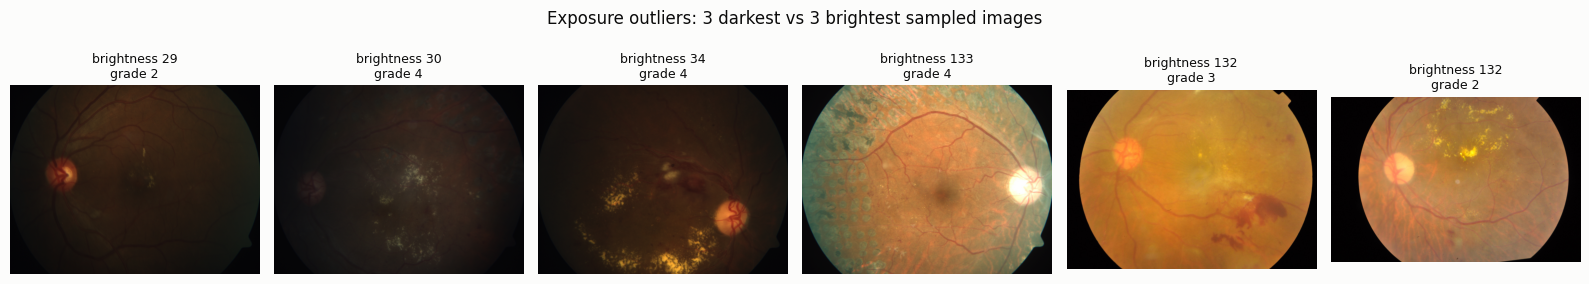

In [10]:
# ===== Cell 11: Plots for resolution and brightness =====
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ax = axes[0]
res = (stats_df["width"].astype(str) + " x " + stats_df["height"].astype(str)).value_counts().head(10)[::-1]
bars = ax.barh(res.index, res.values, color=GRADE_COLORS[0], height=0.7)
ax.bar_label(bars, padding=3, color="#52514e", fontsize=9)
ax.set_title(f"{stats_df[['width','height']].drop_duplicates().shape[0]} different camera resolutions (top 10 shown)")
ax.set_xlabel("Images in 500-image sample"); ax.grid(axis="y", visible=False)

ax = axes[1]
data = [stats_df[stats_df["diagnosis"] == g]["brightness"] for g in range(5)]
bp = ax.boxplot(data, patch_artist=True, widths=0.55,
                medianprops=dict(color="#0b0b0b"))
for patch, c in zip(bp["boxes"], GRADE_COLORS):
    patch.set_facecolor(c); patch.set_alpha(0.75); patch.set_edgecolor("#52514e")
ax.axhline(low, ls="--", color="#898781", lw=1); ax.axhline(high, ls="--", color="#898781", lw=1)
ax.set_xticks(range(1, 6), [grade_labels[g] for g in range(5)], rotation=15)
ax.set_title("Retina brightness per grade (dashed = IQR outlier fence)")
ax.set_ylabel("Mean retina intensity (0-255)")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "image_stats.png", dpi=150)
plt.show()

# show the darkest and brightest sampled images
ext = pd.concat([stats_df.nsmallest(3, "brightness"), stats_df.nlargest(3, "brightness")])
fig, axes = plt.subplots(1, 6, figsize=(16, 3.2))
for ax, (_, r) in zip(axes, ext.iterrows()):
    ax.imshow(read_rgb(IMAGE_DIRS["train"] / f"{r.id_code}.png")); ax.axis("off")
    ax.set_title(f"brightness {r.brightness:.0f}\ngrade {r.diagnosis}", fontsize=9)
plt.suptitle("Exposure outliers: 3 darkest vs 3 brightest sampled images")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "outliers.png", dpi=150)
plt.show()

## 5. Preprocessing & feature engineering
* **Circular crop** - remove the uninformative black border (up to ~40% of pixels) so the network sees retina, not background.
* **Ben Graham local-contrast enhancement** - subtract a Gaussian-blurred copy to normalise illumination across cameras and make microaneurysms / exudates stand out.
* **Resize to 224x224** and **MobileNetV2 `preprocess_input`** (scale to [-1, 1]) - the input the ImageNet weights expect.
* **Augmentation** (training only) - random flips, rotation and zoom: a fundus image has no fixed orientation.
* **Class weights** - counter the 9:1 imbalance.

Outliers are **kept** (not removed): dark/over-exposed images are exactly what a rural PHC camera will produce, so the model must learn them; contrast enhancement reduces their effect.

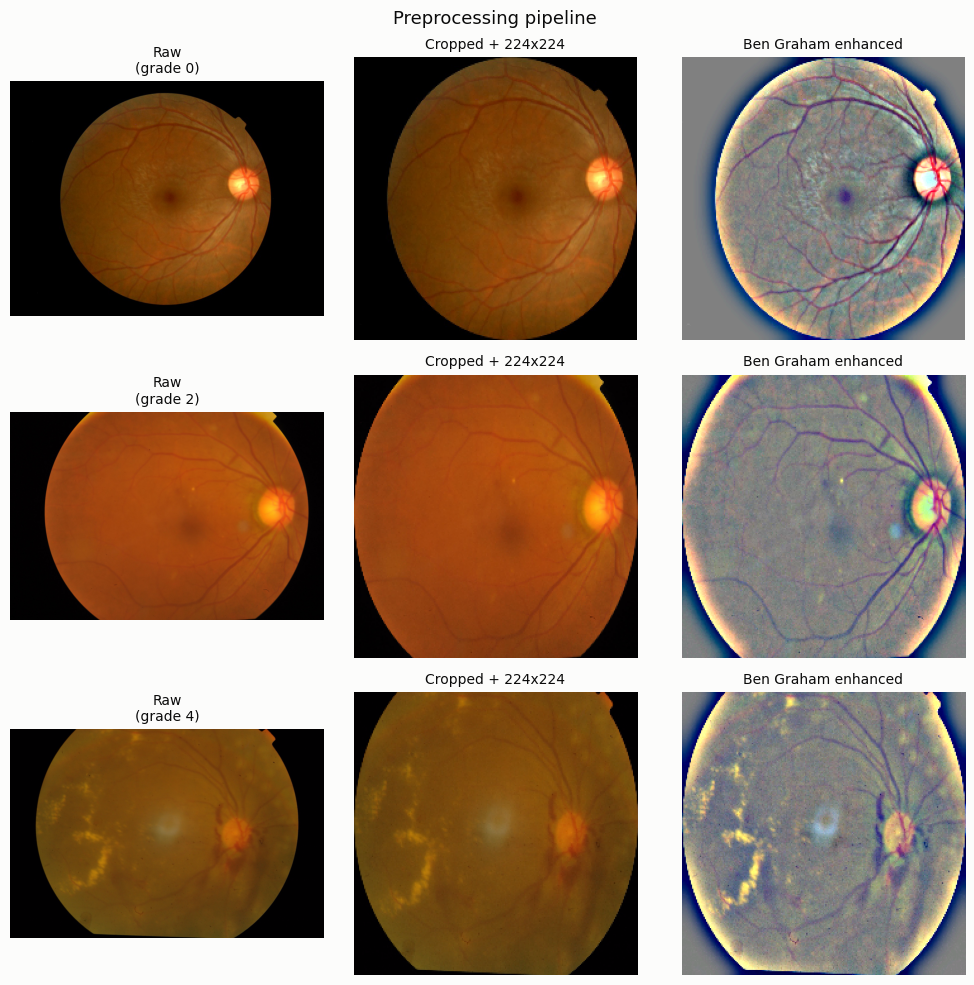

In [11]:
# ===== Cell 12: Preprocessing functions =====
IMG_SIZE = 224

def crop_retina(img, tol=10):
    """Crop away the black background around the circular fundus."""
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    mask = gray > tol
    if not mask.any():
        return img
    rows, cols = np.where(mask)
    return img[rows.min():rows.max() + 1, cols.min():cols.max() + 1]

def ben_graham(img, sigma=IMG_SIZE / 30):
    """Local contrast normalisation (Ben Graham, Kaggle DR 2015 winner)."""
    blur = cv2.GaussianBlur(img, (0, 0), sigma)
    return cv2.addWeighted(img, 4, blur, -4, 128)

def load_for_model(path):
    """Exact preprocessing used for the trained checkpoint: resize + MobileNetV2 scaling."""
    img = cv2.resize(read_rgb(path), (IMG_SIZE, IMG_SIZE)).astype("float32")
    return tf.keras.applications.mobilenet_v2.preprocess_input(img)

# visual comparison of each step
demo_ids = [train_df[train_df["diagnosis"] == g]["id_code"].iloc[0] for g in (0, 2, 4)]
fig, axes = plt.subplots(3, 3, figsize=(10, 10))
for r, img_id in enumerate(demo_ids):
    raw = read_rgb(IMAGE_DIRS["train"] / f"{img_id}.png")
    cropped = cv2.resize(crop_retina(raw), (IMG_SIZE, IMG_SIZE))
    enhanced = ben_graham(cropped)
    for c, (im, t) in enumerate([(raw, "Raw"), (cropped, "Cropped + 224x224"), (enhanced, "Ben Graham enhanced")]):
        axes[r, c].imshow(im); axes[r, c].axis("off")
        axes[r, c].set_title(f"{t}" + (f"\n(grade {train_df.set_index('id_code').loc[img_id,'diagnosis']})" if c == 0 else ""), fontsize=10)
plt.suptitle("Preprocessing pipeline", fontsize=13)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "preprocessing.png", dpi=150)
plt.show()

In [12]:
# ===== Cell 13: Class weights for imbalance =====
from sklearn.utils.class_weight import compute_class_weight
weights = compute_class_weight("balanced", classes=np.arange(5), y=train_df["diagnosis"])
class_weight = {i: round(float(w), 3) for i, w in enumerate(weights)}
print(pd.DataFrame({"grade": [grade_labels[i] for i in range(5)],
                    "train_images": counts.values,
                    "class_weight": list(class_weight.values())}).to_string(index=False))

           grade  train_images  class_weight
           No DR          1434         0.409
            Mild           300         1.953
        Moderate           808         0.725
          Severe           154         3.805
Proliferative DR           234         2.504


## 6. Model selection & justification

| Option | Why not (for this data / setting) |
|---|---|
| Classical ML (SVM / Random Forest on hand-crafted features) | Lesions are tiny (microaneurysms ~10 px); hand-crafted colour/texture features miss them. Benchmarked CNNs dominate APTOS. |
| CNN trained from scratch | Only 2,930 training images - would overfit badly. |
| ResNet50 / InceptionV3 | 23-25 M params, ~100 MB, slow on a PHC CPU laptop. |
| EfficientNet-B3+/ ViT | Best Kaggle scores but need GPU + large data; ViT is data-hungry. |
| **MobileNetV2 (chosen)** | ImageNet transfer learning works with small data; 2.3 M params / 8.7 MB; real-time on CPU / Raspberry Pi; final conv map (7x7x1280) gives clean Grad-CAM heatmaps. |

Head: GlobalAveragePooling -> Dropout -> Dense(5, softmax). Backbone frozen for phase-1 (feature extraction); fine-tuning is planned for phase 2.

In [13]:
# ===== Cell 14: Model definition and (optional) training =====
# Training was run earlier (12 epochs, Adam, categorical cross-entropy) and produced
# best_retinopathy.keras + training_log.csv. Set TRAIN = True to re-run it (slow on CPU).
TRAIN = False
MODEL_PATH = Path("best_retinopathy.keras")

def build_model(dropout=0.2):
    base = tf.keras.applications.MobileNetV2(input_shape=(IMG_SIZE, IMG_SIZE, 3),
                                             include_top=False, weights="imagenet")
    base.trainable = False                      # phase 1: feature extraction
    inputs = tf.keras.Input((IMG_SIZE, IMG_SIZE, 3))
    x = base(inputs, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dropout(dropout)(x)
    outputs = tf.keras.layers.Dense(5, activation="softmax")(x)
    model = tf.keras.Model(inputs, outputs)
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                  loss="categorical_crossentropy", metrics=["accuracy"])
    return model

def make_dataset(df, split, shuffle=False, augment=False, batch=32):
    paths = [str(IMAGE_DIRS[split] / f"{i}.png") for i in df["id_code"]]
    labels = tf.keras.utils.to_categorical(df["diagnosis"], 5)
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    def _load(p, y):
        img = tf.image.decode_png(tf.io.read_file(p), channels=3)
        img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
        return tf.keras.applications.mobilenet_v2.preprocess_input(img), y
    ds = ds.map(_load, num_parallel_calls=tf.data.AUTOTUNE)
    if shuffle:
        ds = ds.shuffle(1000, seed=42)
    if augment:
        aug = tf.keras.Sequential([tf.keras.layers.RandomFlip("horizontal_and_vertical"),
                                   tf.keras.layers.RandomRotation(0.1),
                                   tf.keras.layers.RandomZoom(0.1)])
        ds = ds.map(lambda x, y: (aug(x, training=True), y), num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(batch).prefetch(tf.data.AUTOTUNE)

if TRAIN:
    model = build_model()
    callbacks = [tf.keras.callbacks.ModelCheckpoint(MODEL_PATH, monitor="val_accuracy", save_best_only=True),
                 tf.keras.callbacks.CSVLogger("training_log.csv"),
                 tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True)]
    model.fit(make_dataset(train_df, "train", shuffle=True, augment=True),
              validation_data=make_dataset(valid_df, "valid"),
              epochs=12, class_weight=class_weight, callbacks=callbacks)

model = tf.keras.models.load_model(MODEL_PATH)
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 5)              │         6,405 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,277,201 (8.69 MB)

 Trainable params: 6,405 (25.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

 Optimizer params: 12,812 (50.05 KB)

## 7. Training progress

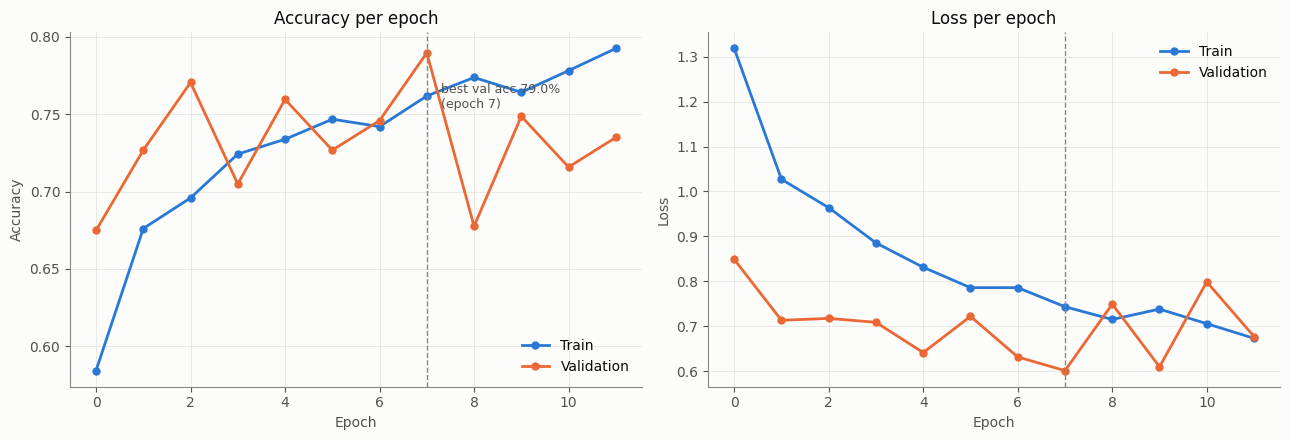

In [14]:
# ===== Cell 15: Learning curves from training_log.csv =====
log = pd.read_csv("training_log.csv")
best = log.loc[log["val_accuracy"].idxmax()]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, metric, title in [(axes[0], "accuracy", "Accuracy"), (axes[1], "loss", "Loss")]:
    ax.plot(log["epoch"], log[metric], color=GRADE_COLORS[0], lw=2, marker="o", ms=5, label="Train")
    ax.plot(log["epoch"], log[f"val_{metric}"], color=GRADE_COLORS[1], lw=2, marker="o", ms=5, label="Validation")
    ax.axvline(best["epoch"], color="#898781", ls="--", lw=1)
    ax.set_title(f"{title} per epoch"); ax.set_xlabel("Epoch"); ax.set_ylabel(title)
    ax.legend(frameon=False)
axes[0].annotate(f"best val acc {best['val_accuracy']:.1%}\n(epoch {int(best['epoch'])})",
                 (best["epoch"], best["val_accuracy"]), xytext=(10, -40), textcoords="offset points",
                 fontsize=9, color="#52514e")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "training_curves.png", dpi=150)
plt.show()

## 8. Evaluation on the held-out test set (366 images)
Metrics: accuracy, macro-F1, **Quadratic Weighted Kappa** (official APTOS metric - penalises predictions far from the true grade), and the clinically relevant **referable-DR** (grade >= 2) sensitivity / specificity.

In [15]:
# ===== Cell 16: Predict on the test set =====
from sklearn.metrics import (accuracy_score, f1_score, cohen_kappa_score, classification_report,
                             confusion_matrix, roc_auc_score, roc_curve)
test_ds = make_dataset(test_df, "test")
probs = model.predict(test_ds, verbose=0)
y_true = test_df["diagnosis"].values
y_pred = probs.argmax(1)

acc = accuracy_score(y_true, y_pred)
f1m = f1_score(y_true, y_pred, average="macro")
qwk = cohen_kappa_score(y_true, y_pred, weights="quadratic")

ref_true = (y_true >= 2).astype(int)
ref_score = probs[:, 2:].sum(1)               # P(referable)
ref_pred = (ref_score >= 0.5).astype(int)
tn, fp, fn, tp = confusion_matrix(ref_true, ref_pred).ravel()
sens, spec = tp / (tp + fn), tn / (tn + fp)
auc = roc_auc_score(ref_true, ref_score)

print(f"Accuracy          : {acc:.4f}")
print(f"Macro F1          : {f1m:.4f}")
print(f"Quadratic Kappa   : {qwk:.4f}")
print(f"Referable DR  ->  sensitivity {sens:.4f} | specificity {spec:.4f} | ROC-AUC {auc:.4f}")
print()
print(classification_report(y_true, y_pred, target_names=[grade_labels[i] for i in range(5)], digits=3))

metrics = {"test_accuracy": acc, "macro_f1": f1m, "quadratic_kappa": qwk,
           "referable_sensitivity": sens, "referable_specificity": spec, "referable_auc": auc,
           "best_val_accuracy": float(best["val_accuracy"]), "best_epoch": int(best["epoch"]),
           "per_class": classification_report(y_true, y_pred, output_dict=True,
                                              target_names=[grade_labels[i] for i in range(5)])}
with open(RESULTS_DIR / "metrics.json", "w") as f:
    json.dump(metrics, f, indent=2, default=float)

Accuracy          : 0.7732
Macro F1          : 0.5589
Quadratic Kappa   : 0.8370
Referable DR  ->  sensitivity 0.9197 | specificity 0.9389 | ROC-AUC 0.9803

                  precision    recall  f1-score   support

           No DR      0.974     0.960     0.967       199
            Mild      0.457     0.533     0.492        30
        Moderate      0.682     0.690     0.686        87
          Severe      0.231     0.353     0.279        17
Proliferative DR      0.476     0.303     0.370        33

        accuracy                          0.773       366
       macro avg      0.564     0.568     0.559       366
    weighted avg      0.783     0.773     0.776       366



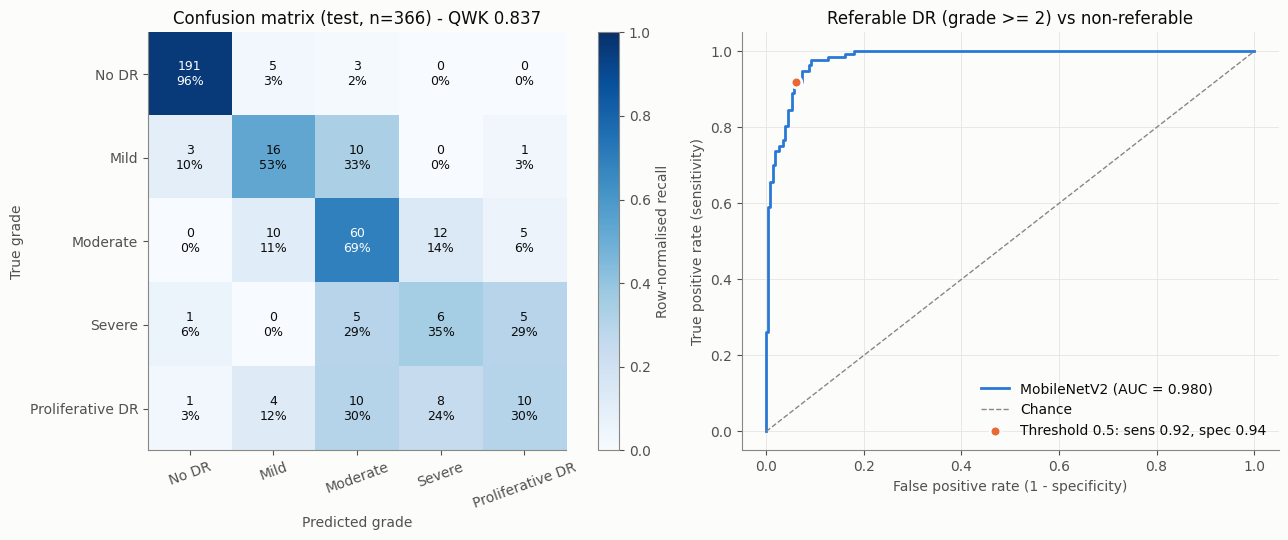

In [16]:
# ===== Cell 17: Confusion matrix and referable-DR ROC =====
cm = confusion_matrix(y_true, y_pred, labels=range(5))
cm_norm = cm / cm.sum(1, keepdims=True)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1.2, 1]})
ax = axes[0]
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
for i in range(5):
    for j in range(5):
        ax.text(j, i, f"{cm[i, j]}\n{cm_norm[i, j]:.0%}", ha="center", va="center", fontsize=9,
                color="white" if cm_norm[i, j] > 0.55 else "#0b0b0b")
names = [grade_labels[i] for i in range(5)]
ax.set_xticks(range(5), names, rotation=20); ax.set_yticks(range(5), names)
ax.set_xlabel("Predicted grade"); ax.set_ylabel("True grade"); ax.grid(False)
ax.set_title(f"Confusion matrix (test, n={len(y_true)}) - QWK {qwk:.3f}")
fig.colorbar(im, ax=ax, fraction=0.046, label="Row-normalised recall")

ax = axes[1]
fpr, tpr, _ = roc_curve(ref_true, ref_score)
ax.plot(fpr, tpr, color=GRADE_COLORS[0], lw=2, label=f"MobileNetV2 (AUC = {auc:.3f})")
ax.plot([0, 1], [0, 1], ls="--", color="#898781", lw=1, label="Chance")
ax.scatter([1 - spec], [sens], s=60, color=GRADE_COLORS[1], zorder=3, edgecolor="#fcfcfb", linewidth=2,
           label=f"Threshold 0.5: sens {sens:.2f}, spec {spec:.2f}")
ax.set_xlabel("False positive rate (1 - specificity)"); ax.set_ylabel("True positive rate (sensitivity)")
ax.set_title("Referable DR (grade >= 2) vs non-referable")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "evaluation.png", dpi=150)
plt.show()

## 9. Explainability - Grad-CAM
Grad-CAM weights the last convolutional feature map (7x7x1280) by the gradient of the predicted class score, producing a heatmap of *where* the model looked. A clinician can check that a 'Moderate/Severe' call is driven by haemorrhages/exudates and not by the image border or camera artefacts - this is what makes the screening tool trustworthy for ASHA / PHC staff.

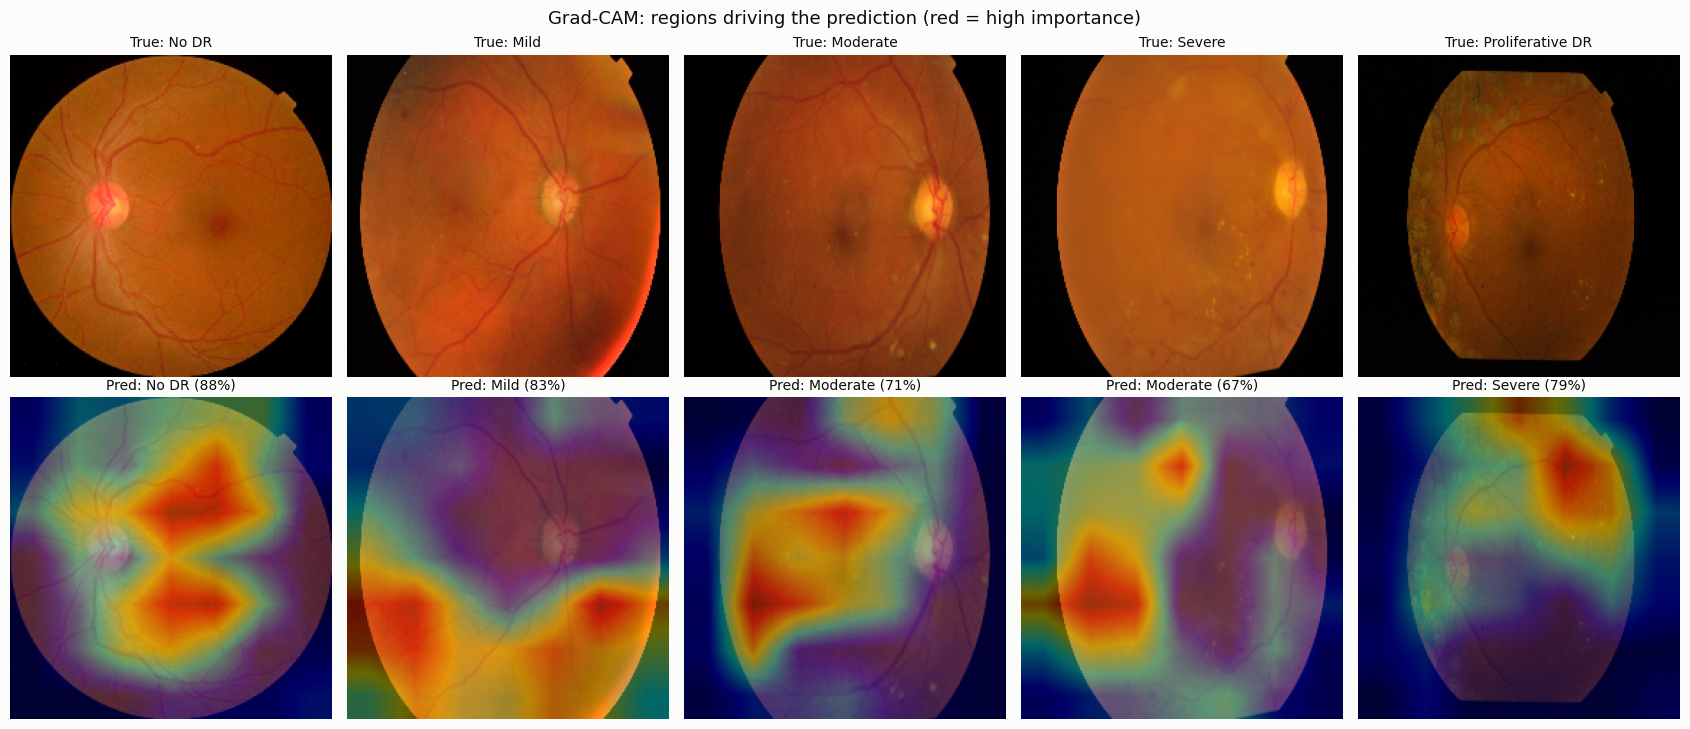

In [17]:
# ===== Cell 18: Grad-CAM =====
backbone = model.get_layer("mobilenetv2_1.00_224")
gap_layer = model.get_layer("global_average_pooling2d")
dense_layer = model.get_layer("dense")

def grad_cam(x, class_idx=None):
    """x: preprocessed image (224,224,3). Returns heatmap (224,224) in [0,1], probs."""
    x = tf.convert_to_tensor(x[None])
    with tf.GradientTape() as tape:
        fmap = backbone(x, training=False)          # (1,7,7,1280) = output of last conv block
        tape.watch(fmap)
        p = dense_layer(gap_layer(fmap))
        if class_idx is None:
            class_idx = int(tf.argmax(p[0]))
        score = p[:, class_idx]
    grads = tape.gradient(score, fmap)[0]
    weights = tf.reduce_mean(grads, axis=(0, 1))
    cam = tf.nn.relu(tf.reduce_sum(fmap[0] * weights, axis=-1)).numpy()
    cam = cv2.resize(cam, (IMG_SIZE, IMG_SIZE))
    cam = cam / (cam.max() + 1e-8)
    return cam, p.numpy()[0]

fig, axes = plt.subplots(2, 5, figsize=(17, 7.5))
for g in range(5):
    img_id = test_df[test_df["diagnosis"] == g]["id_code"].iloc[0]
    path = IMAGE_DIRS["test"] / f"{img_id}.png"
    raw = cv2.resize(read_rgb(path), (IMG_SIZE, IMG_SIZE))
    cam, p = grad_cam(load_for_model(path))
    pred = int(p.argmax())
    axes[0, g].imshow(raw); axes[0, g].axis("off")
    axes[0, g].set_title(f"True: {grade_labels[g]}", fontsize=10)
    heat = cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET)[..., ::-1]
    axes[1, g].imshow(np.uint8(0.6 * raw + 0.4 * heat)); axes[1, g].axis("off")
    axes[1, g].set_title(f"Pred: {grade_labels[pred]} ({p[pred]:.0%})", fontsize=10)
plt.suptitle("Grad-CAM: regions driving the prediction (red = high importance)", fontsize=13)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "gradcam.png", dpi=150)
plt.show()

In [18]:
# ===== Cell 19: Screening report for one patient (prototype output) =====
# Purpose: what a PHC health worker would see - grade, confidence, referral advice and heatmap.
ACTIONS = {0: "Routine re-screening in 12 months", 1: "Re-screen in 6-12 months",
           2: "Refer to ophthalmologist within 3 months", 3: "Urgent referral (2-4 weeks)",
           4: "Immediate referral - sight-threatening"}

def screen(path):
    x = load_for_model(path)
    cam, p = grad_cam(x)
    g = int(p.argmax())
    return {"image": Path(path).name, "grade": g, "diagnosis": grade_labels[g],
            "confidence": round(float(p[g]), 3), "referable": g >= 2,
            "action": ACTIONS[g], "probabilities": {grade_labels[i]: round(float(v), 3) for i, v in enumerate(p)}}

example = IMAGE_DIRS["test"] / f"{test_df['id_code'].iloc[1]}.png"
print(json.dumps(screen(example), indent=2))

{
  "image": "e4e343eaae2a.png",
  "grade": 2,
  "diagnosis": "Moderate",
  "confidence": 0.706,
  "referable": true,
  "action": "Refer to ophthalmologist within 3 months",
  "probabilities": {
    "No DR": 0.001,
    "Mild": 0.165,
    "Moderate": 0.706,
    "Severe": 0.037,
    "Proliferative DR": 0.092
  }
}


## 10. Mid-term status & next steps
**Done:** data audit, EDA, outlier analysis, preprocessing pipeline, MobileNetV2 baseline (frozen backbone), test evaluation (QWK, referable-DR sensitivity), Grad-CAM explanations, prototype screening function.

**Next:** fine-tune top MobileNetV2 blocks with Ben Graham inputs + class weights; ordinal/regression head with optimised thresholds; improve Mild/Severe recall; FastAPI service + simple web UI for PHC use; TFLite export for offline devices.